# RQ1: Addressed Code Review Tasks


In [1]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter


In [2]:
INPUT_JSONL = "../data/parsed_extracted_data.jsonl"

records = []
with open(INPUT_JSONL, "r", encoding="utf-8") as f:
    for line in f:
        records.append(json.loads(line))

print(f"Loaded {len(records)} records")
print(records[0].keys())


Loaded 165 records
dict_keys(['Done ?', 'Who?', 'ID', 'Title', 'Authors', 'Venue type', 'Venue', 'Year', 'Task', 'Automation level', 'Model', 'Learning type', 'Model category', 'Model subcategory', 'Training method', 'Input features', 'Pre-processing techniques', 'Encoding techniques', 'Output', 'Dataset availability', 'Dataset', 'Dataset size', 'Language', 'Evaluation type', 'Evaluation method', 'Metrics', 'Baseline', 'Replication package', 'Challenges', 'Remarks', 'Task_Categories'])


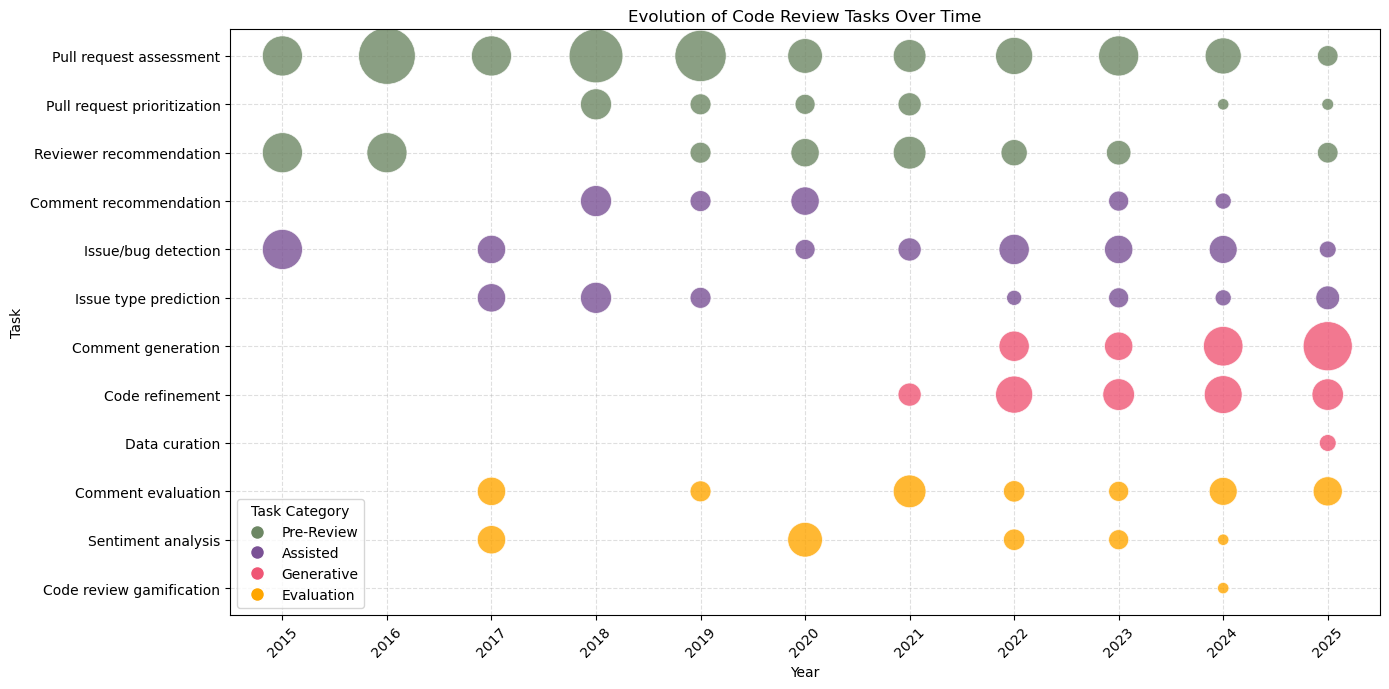

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba

df = pd.DataFrame(records)

# 1. Task → taxonomy type mapping (COLOR ONLY)

TASK_TYPE_MAP = {
    "Pull request assessment": "Pre-Review",
    "Reviewer recommendation": "Pre-Review",
    "Pull request prioritization": "Pre-Review",
    # Assisted
    "Issue/bug detection": "Assisted",
    "Issue type prediction": "Assisted",
    "Comment recommendation": "Assisted",
    # Generative
    "Comment generation": "Generative",
    "Code refinement": "Generative",
    "Data curation": "Generative",
    # Evaluation
    "Comment evaluation": "Evaluation",
    "Sentiment analysis": "Evaluation",
    "Code review gamification": "Evaluation",
}


def map_task_types(task_list):
    return [TASK_TYPE_MAP[t] for t in task_list]


df["TaskType"] = df["Task"].apply(map_task_types)


# 2. Explode tasks (1 row = 1 paper × 1 task)

df_exploded = df.explode(["Task", "TaskType"])

# 3. Compute percentages per year

total_per_year = (
    df_exploded.groupby("Year")["ID"].nunique().reset_index(name="TotalPapers")
)

task_year_counts = (
    df_exploded.groupby(["Year", "Task", "TaskType"])["ID"]
    .nunique()
    .reset_index(name="TaskPapers")
)

plot_df = task_year_counts.merge(total_per_year, on="Year")
plot_df["Percentage"] = plot_df["TaskPapers"] / plot_df["TotalPapers"]

# 4. FINAL Y-axis order (taxonomy enforced HERE)

TASK_ORDER = [
    "Pull request assessment",
    "Pull request prioritization",
    "Reviewer recommendation",
    "Comment recommendation",
    "Issue/bug detection",
    "Issue type prediction",
    "Comment generation",
    "Code refinement",
    "Data curation",
    "Comment evaluation",
    "Sentiment analysis",
    "Code review gamification",
]

plot_df["Task"] = pd.Categorical(plot_df["Task"], categories=TASK_ORDER, ordered=True)

# IMPORTANT: sort ONLY by Task
plot_df = plot_df.sort_values("Task")

# 5. Bubble plot (percentage-based)

TYPE_COLORS = {
    "Pre-Review": "#FAD7AC",
    "Assisted": "#BAC8D3",
    "Generative": "#D0CEE2",
    "Evaluation": "#D5E8D4",
}

TYPE_COLORS = {
    "Pre-Review": "#6D8764",
    "Assisted": "#7a5195",
    "Generative": "#ef5675",
    "Evaluation": "#ffa600",
}

fig, ax = plt.subplots(figsize=(14, 7))

# Categorical plots need this
ax.invert_yaxis()

SIZE_SCALE = 2500

for task_type, color in TYPE_COLORS.items():
    subset = plot_df[plot_df["TaskType"] == task_type]

    ax.scatter(
        subset["Year"],
        subset["Task"],
        s=subset["Percentage"] * SIZE_SCALE,
        color=color,
        alpha=0.8,
        edgecolors="white",
        linewidth=0.6,
    )

# 6. Axes, ticks, legend, styling

years = sorted(plot_df["Year"].unique())
ax.set_xticks(years)
ax.set_xticklabels(years, rotation=45)

ax.set_xlabel("Year")
ax.set_ylabel("Task")
ax.set_title("Evolution of Code Review Tasks Over Time")

ax.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=color,
        markeredgecolor="white",
        markersize=10,
        label=task_type,
    )
    for task_type, color in TYPE_COLORS.items()
]

ax.legend(
    handles=legend_handles,
    title="Task Category",
    frameon=True,
)

plt.savefig("tasks_temporal_evol.pdf", bbox_inches="tight")

plt.tight_layout()
plt.show()


In [6]:
df["TaskType"].value_counts()


TaskType
[Pre-Review]                                      56
[Generative]                                      36
[Assisted]                                        23
[Evaluation]                                      22
[Generative, Generative]                           4
[Generative, Generative, Pre-Review]               4
[Generative, Evaluation]                           3
[Generative, Assisted, Pre-Review]                 2
[Assisted, Generative, Assisted]                   2
[Assisted, Assisted]                               2
[Assisted, Pre-Review]                             2
[Evaluation, Evaluation]                           1
[Generative, Assisted, Generative, Pre-Review]     1
[Assisted, Evaluation, Assisted]                   1
[Generative, Assisted, Generative]                 1
[Pre-Review, Pre-Review]                           1
[Generative, Assisted, Evaluation]                 1
[Pre-Review, Generative]                           1
[Generative, Generative, Evaluation] 

In [7]:
df["TaskType"].isna().sum(), df["Task"].isna().sum()


(np.int64(0), np.int64(0))

In [8]:
plot_df.shape


(68, 6)

In [9]:
plot_df.head()


,Year,Task,TaskType,TaskPapers,TotalPapers,Percentage
56,2024,Pull request assessment,Pre-Review,10,37,0.270270
17,2019,Pull request assessment,Pre-Review,6,11,0.545455
22,2020,Pull request assessment,Pre-Review,3,12,0.250000
12,2018,Pull request assessment,Pre-Review,3,5,0.600000
37,2022,Pull request assessment,Pre-Review,6,21,0.285714


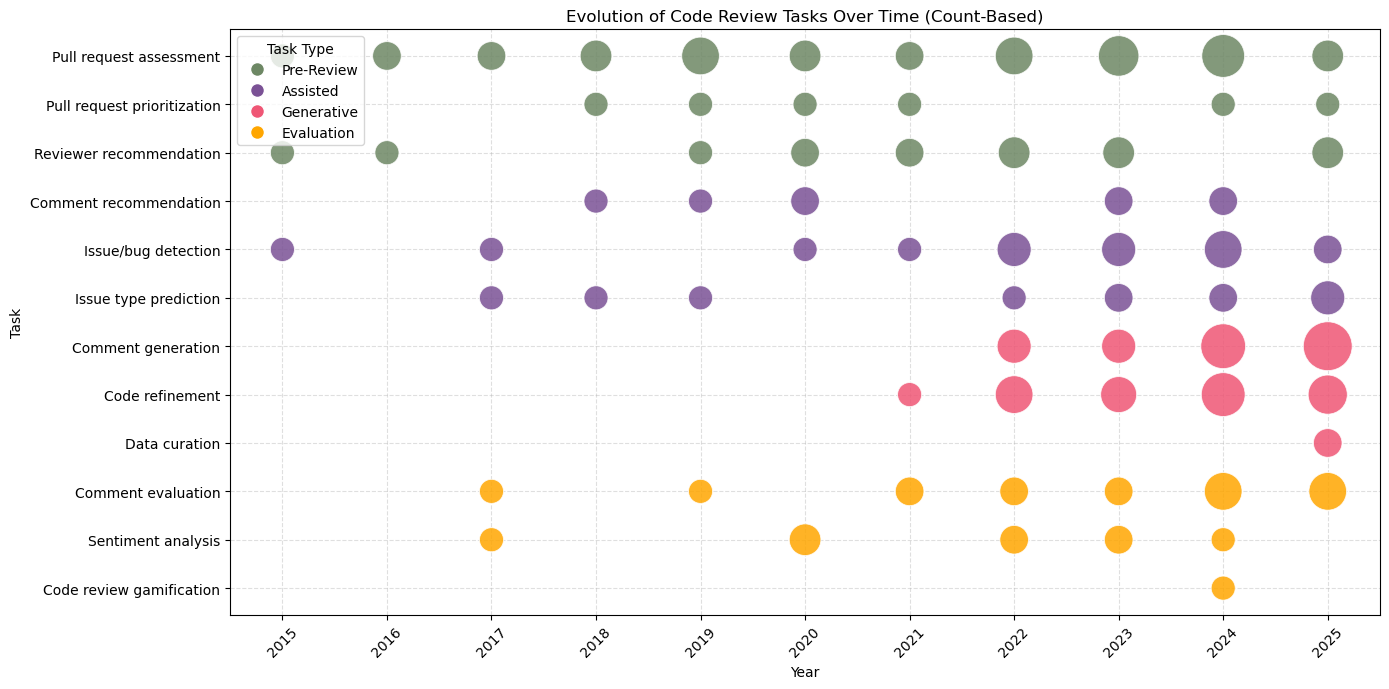

In [10]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# SECOND FIGURE: Count-based bubble plot
# (taxonomy order already enforced in plot_df["Task"])

# Alias count for clarity
plot_df["Count"] = plot_df["TaskPapers"]

fig, ax = plt.subplots(figsize=(14, 7))

# IMPORTANT: categorical Y-axis direction
ax.invert_yaxis()

# Bubble size scaling (COUNT-based)
# Recommended for papers: perceptual (sqrt) scaling
USE_SQRT = True
SIZE_SCALE = 300  # only used if USE_SQRT = False

for task_type, color in TYPE_COLORS.items():
    subset = plot_df[plot_df["TaskType"] == task_type]

    if USE_SQRT:
        sizes = np.sqrt(subset["Count"]) * 300
    else:
        sizes = subset["Count"] * SIZE_SCALE

    ax.scatter(
        subset["Year"],
        subset["Task"],
        s=sizes,
        color=color,
        alpha=0.85,
        edgecolors="white",
        linewidth=0.6,
    )


years = sorted(plot_df["Year"].unique())
ax.set_xticks(years)
ax.set_xticklabels(years, rotation=45)

ax.set_xlabel("Year")
ax.set_ylabel("Task")
ax.set_title("Evolution of Code Review Tasks Over Time (Count-Based)")

ax.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Fixed-size legend (color only)

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=color,
        markeredgecolor="white",
        markersize=10,
        label=task_type,
    )
    for task_type, color in TYPE_COLORS.items()
]

ax.legend(
    handles=legend_handles,
    title="Task Type",
    frameon=True,
    loc="upper left",
)

plt.tight_layout()
plt.show()


In [11]:
import pandas as pd
import numpy as np

# Helpers


def latex_escape(text):
    """Escape LaTeX special characters."""
    if pd.isna(text):
        return ""
    text = str(text)
    replacements = {
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
        "\\": r"\textbackslash{}",
    }
    for k, v in replacements.items():
        text = text.replace(k, v)
    return text


def repl_symbol(value):
    """Map replication package status to LaTeX symbol."""
    if pd.isna(value):
        return r"$\times$"
    v = str(value).lower().strip()
    if v == "available":
        return r"\checkmark"
    if v == "partially available":
        return r"$\sim$"
    return r"$\times$"


# Task Category → LaTeX bullet mapping
# (MATCHES YOUR COMMANDS EXACTLY)

TASK_CATEGORY_LATEX = {
    "Pre-Review": r"{\LARGE\textcolor{PreReviewColor}{\textbullet}}",
    "Assisted": r"{\LARGE\textcolor{AssistedColor}{\textbullet}}",
    "Generative": r"{\LARGE\textcolor{GenerativeColor}{\textbullet}}",
    "Evaluation": r"{\LARGE\textcolor{EvaluationColor}{\textbullet}}",
}

# Order in which bullets appear in the table
TASK_CATEGORY_ORDER = [
    "Pre-Review",
    "Assisted",
    "Generative",
    "Evaluation",
]


def task_category_bullets(task_types):
    """
    Convert a list of task categories into ordered LaTeX bullets.
    """
    if not isinstance(task_types, (list, tuple)):
        return ""

    cats = sorted(set(task_types), key=lambda x: TASK_CATEGORY_ORDER.index(x))
    return " ".join(TASK_CATEGORY_LATEX[c] for c in cats if c in TASK_CATEGORY_LATEX)


# Sort + reindex papers

df_clean = df.copy()

# Keep only valid years
df_clean = df_clean[pd.notna(df_clean["Year"])]

# Sort by year, then title
df_clean = df_clean.sort_values(
    by=["Year", "Title"], key=lambda x: x if x.name != "Title" else x.str.lower()
).reset_index(drop=True)

# Reindex IDs as P1, P2, ...
df_clean["NewID"] = [f"P{i+1}" for i in range(len(df_clean))]

# Generate LaTeX table

lines = []

lines.append(
    r"\textbf{ID} & \textbf{Title} & \textbf{Task Category} & \textbf{Repl.} \\"
)
lines.append(r"\midrule")

current_year = None

for _, row in df_clean.iterrows():
    year = int(row["Year"])

    if year != current_year:
        if current_year is not None:
            lines.append("")
        lines.append(rf"\midrule\multicolumn{{4}}{{c}}{{\textbf{{{year}}}}} \\")
        lines.append(r"\midrule")
        current_year = year

    pid = row["NewID"]
    title = latex_escape(row["Title"])
    task_cat = task_category_bullets(row["TaskType"])
    repl = repl_symbol(row["Replication package"])

    lines.append(f"{pid} & {title} & {task_cat} & {repl} \\\\")

# Output

latex_output = "\n".join(lines)
print(latex_output)


\textbf{ID} & \textbf{Title} & \textbf{Task Category} & \textbf{Repl.} \\
\midrule
\midrule\multicolumn{4}{c}{\textbf{2015}} \\
\midrule
P1 & Supporting Code Review by Automatic Detection of Potentially Buggy Changes & {\LARGE\textcolor{AssistedColor}{\textbullet}} & \checkmark \\
P2 & Who should review this change?: Putting text and file location analyses together for more accurate recommendations & {\LARGE\textcolor{PreReviewColor}{\textbullet}} & $\times$ \\
P3 & Will they like this? evaluating code contributions with language models & {\LARGE\textcolor{PreReviewColor}{\textbullet}} & $\times$ \\

\midrule\multicolumn{4}{c}{\textbf{2016}} \\
\midrule
P4 & Predicting Defectiveness of Software Patches & {\LARGE\textcolor{PreReviewColor}{\textbullet}} & $\times$ \\
P5 & Reviewer recommendation for pull-requests in GitHub: What can we learn from code review and bug assignment? & {\LARGE\textcolor{PreReviewColor}{\textbullet}} & $\times$ \\
P6 & Testing and Code Review Based Effort-Aware

In [12]:
import pandas as pd

# Helpers


def latex_escape(text):
    """Escape LaTeX special characters."""
    if pd.isna(text):
        return ""
    text = str(text)
    replacements = {
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
        "\\": r"\textbackslash{}",
    }
    for k, v in replacements.items():
        text = text.replace(k, v)
    return text


def availability_symbol(value):
    """
    Map availability status to LaTeX symbol.
    Uses your predefined \\partialrep command.
    """
    if pd.isna(value):
        return r"$\times$"
    v = str(value).lower().strip()
    if v == "available":
        return r"\checkmark"
    if v == "partially available":
        return r"\partialrep"
    return r"$\times$"


# Task Category → LaTeX bullets (EXACT match)

TASK_CATEGORY_LATEX = {
    "Pre-Review": r"{\LARGE\textcolor{PreReviewColor}{\textbullet}}",
    "Assisted": r"{\LARGE\textcolor{AssistedColor}{\textbullet}}",
    "Generative": r"{\LARGE\textcolor{GenerativeColor}{\textbullet}}",
    "Evaluation": r"{\LARGE\textcolor{EvaluationColor}{\textbullet}}",
}

TASK_CATEGORY_ORDER = [
    "Pre-Review",
    "Assisted",
    "Generative",
    "Evaluation",
]


def task_category_bullets(task_types):
    """Convert list of categories into ordered LaTeX bullets."""
    if not isinstance(task_types, (list, tuple)):
        return ""
    cats = sorted(set(task_types), key=lambda c: TASK_CATEGORY_ORDER.index(c))
    return " ".join(TASK_CATEGORY_LATEX[c] for c in cats if c in TASK_CATEGORY_LATEX)


# Sort + reindex papers

df_clean = df.copy()

df_clean = df_clean[pd.notna(df_clean["Year"])]

df_clean = df_clean.sort_values(
    by=["Year", "Title"], key=lambda x: x if x.name != "Title" else x.str.lower()
).reset_index(drop=True)

df_clean["NewID"] = [f"P{i+1}" for i in range(len(df_clean))]

# Generate LaTeX longtable

lines = []

# Header (longtable environment is outside)
lines.append(
    r"\textbf{ID} & \textbf{Title} & \textbf{Task} & \textbf{Repl.} & \textbf{Dataset} \\"
)
lines.append(r"\midrule")

current_year = None

for _, row in df_clean.iterrows():
    year = int(row["Year"])

    if year != current_year:
        if current_year is not None:
            lines.append("")
        lines.append(rf"\midrule\multicolumn{{5}}{{c}}{{\textbf{{{year}}}}} \\")
        lines.append(r"\midrule")
        current_year = year

    pid = row["NewID"]
    title = latex_escape(row["Title"])
    task = task_category_bullets(row["TaskType"])
    repl = availability_symbol(row["Replication package"])
    dataset = availability_symbol(row["Dataset availability"])

    lines.append(f"{pid} & {title} & {task} & {repl} & {dataset} \\\\")

# Output

latex_output = "\n".join(lines)
print(latex_output)


\textbf{ID} & \textbf{Title} & \textbf{Task} & \textbf{Repl.} & \textbf{Dataset} \\
\midrule
\midrule\multicolumn{5}{c}{\textbf{2015}} \\
\midrule
P1 & Supporting Code Review by Automatic Detection of Potentially Buggy Changes & {\LARGE\textcolor{AssistedColor}{\textbullet}} & \checkmark & $\times$ \\
P2 & Who should review this change?: Putting text and file location analyses together for more accurate recommendations & {\LARGE\textcolor{PreReviewColor}{\textbullet}} & $\times$ & \partialrep \\
P3 & Will they like this? evaluating code contributions with language models & {\LARGE\textcolor{PreReviewColor}{\textbullet}} & $\times$ & $\times$ \\

\midrule\multicolumn{5}{c}{\textbf{2016}} \\
\midrule
P4 & Predicting Defectiveness of Software Patches & {\LARGE\textcolor{PreReviewColor}{\textbullet}} & $\times$ & \checkmark \\
P5 & Reviewer recommendation for pull-requests in GitHub: What can we learn from code review and bug assignment? & {\LARGE\textcolor{PreReviewColor}{\textbullet}} & 

In [13]:
df_exploded = df.explode(["Task", "TaskType"])


In [14]:
papers_per_category = (
    df_exploded.groupby("TaskType")["ID"]
    .nunique()
    .reset_index(name="NumPapers")
    .sort_values("NumPapers", ascending=False)
)

print(papers_per_category)


     TaskType  NumPapers
3  Pre-Review         67
2  Generative         57
0    Assisted         35
1  Evaluation         29


In [15]:
papers_per_task_category = (
    df_exploded.groupby(["TaskType", "Task"])["ID"]
    .nunique()
    .reset_index(name="NumPapers")
    .sort_values(["TaskType", "NumPapers"], ascending=[True, False])
)

print(papers_per_task_category)


      TaskType                         Task  NumPapers
2     Assisted          Issue/bug detection         20
1     Assisted        Issue type prediction         12
0     Assisted       Comment recommendation          8
4   Evaluation           Comment evaluation         20
5   Evaluation           Sentiment analysis          9
3   Evaluation     Code review gamification          1
7   Generative           Comment generation         37
6   Generative              Code refinement         30
8   Generative                Data curation          2
9   Pre-Review      Pull request assessment         46
11  Pre-Review      Reviewer recommendation         16
10  Pre-Review  Pull request prioritization          6
